In [1]:
import cPickle as pickle
import os

import numpy as np
import matplotlib.pyplot as plt
import quantities as pq
import scipy.sparse as sparse
from scipy.io import wavfile
from IPython.display import Audio, display

import soundsig
from soundsig.sound import spectrogram, plot_spectrogram

import config

from segment_analysis import MultiSegment
from spikes.plotting import plot_spikes_with_timeseries
from spikes.plotting.segment_view import PlaybacksManager, SegmentViewer, TrialsViewer
from spikes.sorting.preprocess import collect_waveforms
from spikes.utils import bin_spikes

%load_ext autoreload
%autoreload 2

/Users/kevinyu/Projects/songephys/env/lib/python2.7/site-packages/brian/optimiser.py:47: UserWarning: sympy not installed
  warnings.warn('sympy not installed')
/Users/kevinyu/Projects/songephys/env/lib/python2.7/site-packages/brian/equations.py:65: UserWarning: sympy not installed
  warnings.warn('sympy not installed')
/Users/kevinyu/Projects/songephys/env/lib/python2.7/site-packages/brian/synapses/synapses.py:30: UserWarning: sympy not installed: some features in Synapses will not be available
  warnings.warn('sympy not installed: some features in Synapses will not be available')


In [2]:
BIRD_NAME = "LbY6074"
BIRD = "LbY6074__161215_145633"

In [3]:
DATADIR = config.DATADIR
data_path = os.path.join(DATADIR, "birds", BIRD_NAME, BIRD, "spikes", "{}-sorted.pkl".format(BIRD))

In [4]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [8]:
align4 = [0, 7, 16, 80]
align3 = [1, 9, 11, 19, 21, 68, 69, 71, 73, 74, 82, 95, 97, 97, 98]
align2 = [2, 3, 4, 5, 8, 10, 12, 13, 17, 18, 20, 22, 67, 72, 85, 92, 93, 94, 99]

# units_of_interest = [5, 11]
units_of_interest = [11]

In [9]:
print len(align4), len(align3)

4 15


## Response to tutor song

Example tutor song shown

* Spikes convolved with gaussian with width std=0.4ms

* N=19 songs


In [10]:
multiseg = MultiSegment(np.array(block.segments)[align3 + align4])
print multiseg

MultiSegment with 19 Segments, 13 Units, t_start=-0.0s, t_stop=4.9692s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


Compute offsets by aligning to a threshold in mean spectrogram power

In [11]:
plt.clf()
#plot_spectrogram(t[t1:t2], f, basesig)
onset_times_tutor = []
for sid in align3 + align4:
    mmm = 0
    bleh = np.mean(abs(SegmentViewer(block.segments[sid]).spectrogram(source=1)[2])**2, axis=0)
    for i, x in enumerate(bleh[440:1000]):
        if x > 1.6e-7:
            mmm = i
            break
#     print sid, (440 + mmm)/1000.0
    onset_times_tutor.append((440 + mmm)/1000.0)
#     plt.figure()
#     plt.plot(bleh[440:1000])
#     plt.hlines([1.6e-7], 0, 400)
#     plt.vlines([mmm], 0, 1.6e-7)
#     plt.show()

In [12]:
multiseg.set_offsets(onset_times_tutor)
print multiseg

MultiSegment with 19 Segments, 13 Units, t_start=-0.855s, t_stop=4.1302s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


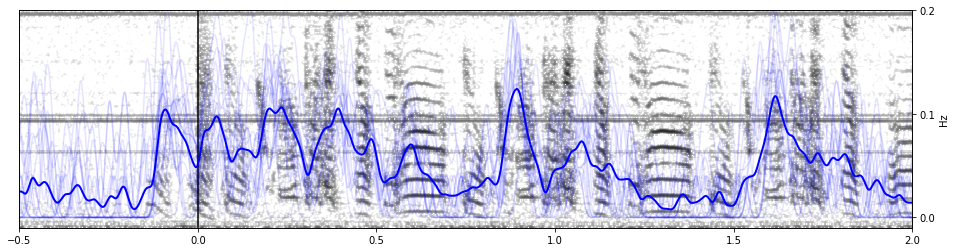

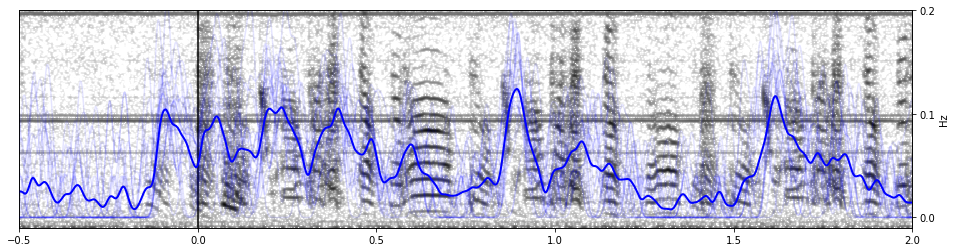

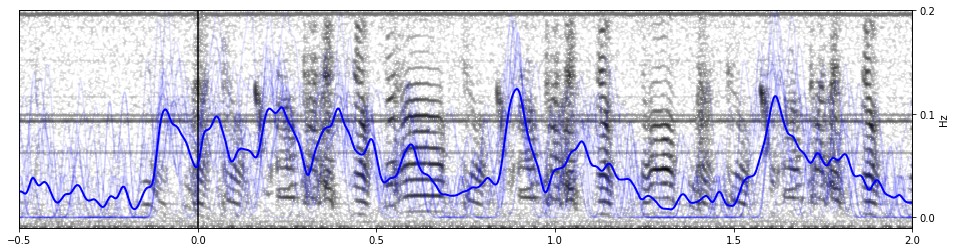

In [25]:
plt.clf()
trials_viewer = TrialsViewer(multiseg)
# seg_viewer = trials_viewer.segment_viewers[0]

for seg_idx, seg_viewer in enumerate(trials_viewer.segment_viewers[:3]):
    for fig_idx, unit in enumerate(units_of_interest):    
        fig, ax = plt.subplots(figsize=(16, 4))
        
        # set t start to align with the reset zero point!
        seg_viewer.plot_spectrogram(ax=ax, source=1, zero_point=np.array(onset_times_tutor)[seg_idx])
        plt.ylabel("")
        plt.xlabel("")
        plt.yticks([])

        ax = ax.twinx()
        trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1)
        plt.yticks([0, 0.1, 0.2])
        plt.ylabel("Hz")
        plt.xlim(-0.5, 2.0)
        plt.ylim(-.01, 0.2)
#         plt.vlines(onset_times_tutor[seg_idx], *plt.ylim())
        plt.vlines(0.0, *plt.ylim())
        # plt.tight_layout()
    plt.show()

## Response to BOS

Onsets aligned, lots of variability in syllable timing though

* Spikes convolved with gaussian with width std=0.4ms

* N=24 songs


In [18]:
alignBOS = [14, 15, 23, 24, 26, 27,28,29,30,32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]
alignBOS = [14, 15, 23, 24, 26,28,29,30,32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]
print len(alignBOS)

24


again, compute offsets to realign

In [19]:
plt.clf()
#plot_spectrogram(t[t1:t2], f, basesig)
onset_times_BOS = []
for sid in alignBOS:
    bleh = np.mean(abs(SegmentViewer(block.segments[sid]).spectrogram(source=1)[2])**2, axis=0)
    for i, x in enumerate(bleh[440:1000]):
        if x > 1e-7:
            mmm = i
            break
#     print sid, (440 + mmm)/1000.0
    onset_times_BOS.append((440 + mmm)/1000.0)
#     plt.figure()
#     plt.plot(bleh[440:1000])
#     plt.hlines([1e-7], 0, 400)
#     plt.vlines([mmm], 0, 1e-7)
#     plt.show()

In [16]:
multiseg_bos = MultiSegment(np.array(block.segments)[alignBOS],
                            np.array(onset_times_BOS))
print multiseg_bos

MultiSegment with 24 Segments, 13 Units, t_start=-0.696s, t_stop=2.89316s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


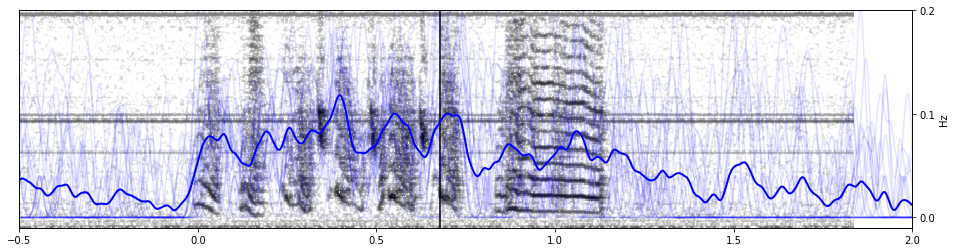

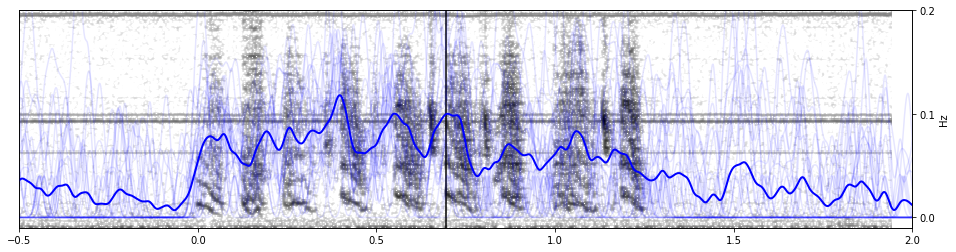

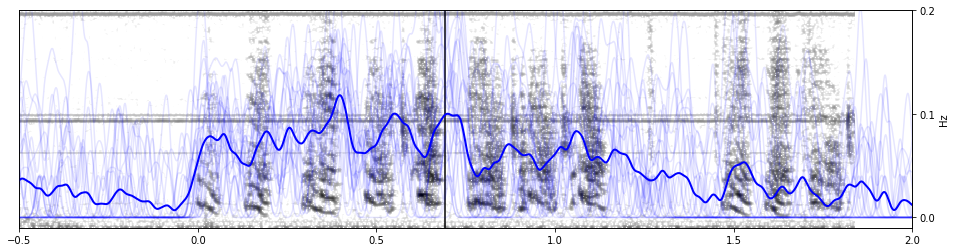

In [26]:
plt.clf()
trials_viewer = TrialsViewer(multiseg_bos)
seg_viewer = trials_viewer.segment_viewers[1]

for seg_idx, seg_viewer in enumerate(trials_viewer.segment_viewers[:3]):
    for fig_idx, unit in enumerate(units_of_interest):    
        fig, ax = plt.subplots(figsize=(16, 4))
        seg_viewer.plot_spectrogram(ax=ax, source=1, zero_point=np.array(onset_times_BOS)[seg_idx])
        plt.ylabel("")
        plt.xlabel("")
        plt.yticks([])

        ax = ax.twinx()
        trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1)
        plt.yticks([0, 0.1, 0.2])
        plt.ylabel("Hz")
        plt.xlim(-0.5, 2.0)
        plt.ylim(-.01, 0.2)
        plt.vlines(onset_times_BOS[seg_idx], *plt.ylim())

        # plt.tight_layout()
    plt.show()

# Crystallized Song Spectrogram

In [12]:
sr, crystallized_song = wavfile.read("/auto/fhome/kevin/Projects/songephys/data/birds/LbY6074/BOS/LBlYel923__January_06_2017_36897275.wav")

In [13]:
t_spec, f_spec, spec, rms = spectrogram(
        crystallized_song - np.mean(crystallized_song),
        sr,
        1000.0,
        50.0,
        min_freq=0,
        max_freq=10000,
        nstd=6)

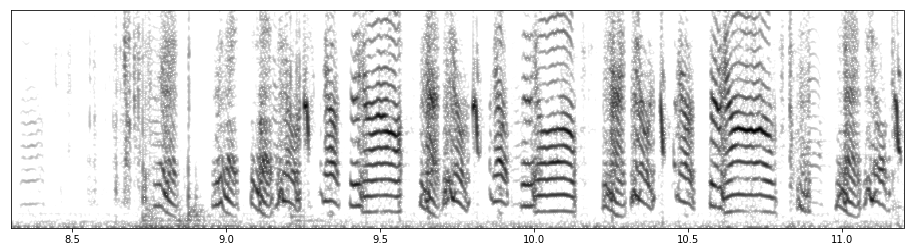

In [14]:
t_spec = t_spec - t_spec[0]

fig, ax = plt.subplots(figsize=(16, 4))
plot_spectrogram(t_spec, f_spec, spec, colormap="gray_r", ax=ax, colorbar=False)
plt.ylabel("")
plt.xlabel("")
plt.yticks([])

plt.xlim(8.3, 11.2)
plt.show()
